# Crypto-Backed Loans: Which Ones Get Liquidated?

With a crypto-backed loan, a user borrows euros and locks bitcoin as collateral. **LTV** (loan-to-value) is the loan divided by the collateral's value. If the bitcoin price falls far enough that LTV reaches 85%, the app sells the collateral to cover the loan: a **liquidation**.

This notebook asks which loans end up liquidated, and when.

**Data:** synthetic, generated by [make_data.py](make_data.py). The bitcoin prices are real (daily BTC/USDT closes from [../bitcoin_forecast](../bitcoin_forecast)), so liquidations happen on the dates the real market fell. Dollar prices are used as a stand-in for euro prices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
loans = pd.read_csv("loans.csv", parse_dates=["issued", "closed"])
btc = pd.read_csv("../bitcoin_forecast/btc_usdt_daily.csv", parse_dates=["date"], index_col="date")["close"]
print(f"{len(loans):,} loans issued {loans.issued.min():%b %Y} to {loans.issued.max():%b %Y}")
loans.head()

508 loans issued Jan 2024 to Oct 2025


,loan_id,user_id,issued,amount_eur,collateral_coin,collateral_amount,ltv_at_issue,annual_rate,term_days,status,closed,close_reason
0,L0109,100037,2024-01-21,1280.0,BTC,0.102613,0.3,0.069,365,repaid,2024-11-25,NaN
1,L0189,100526,2024-03-05,2210.0,BTC,0.115603,0.3,0.069,90,repaid,2024-05-29,NaN
2,L0268,100157,2024-03-16,670.0,BTC,0.020520,0.5,0.099,90,repaid,2024-05-04,NaN
3,L0256,100034,2024-03-29,2260.0,BTC,0.107849,0.3,0.129,180,repaid,2024-08-06,NaN
4,L0630,100371,2024-04-17,3000.0,BTC,0.097915,0.5,0.129,365,repaid,2025-03-03,NaN


In [3]:
loans.status.value_counts().rename("loans")

status
repaid        371
active         76
liquidated     61
Name: loans, dtype: int64

## 1. Starting LTV decides almost everything

In [4]:
by_ltv = loans.groupby("ltv_at_issue").agg(loans=("loan_id", "size"),
                                          liquidated=("status", lambda s: (s == "liquidated").mean()))
by_ltv.round(3)

,loans,liquidated
ltv_at_issue,,
0.3,124,0.000
0.5,220,0.000
0.7,164,0.372


How far does bitcoin have to fall before a loan is liquidated? LTV rises as the price falls, so a loan reaches 85% LTV when the price drops by 1 − (starting LTV ÷ 0.85):

In [5]:
for ltv in [0.3, 0.5, 0.7]:
    print(f"starting LTV {ltv:.0%}: liquidated after a {1 - ltv / 0.85:.0%} fall in bitcoin")

starting LTV 30%: liquidated after a 65% fall in bitcoin
starting LTV 50%: liquidated after a 41% fall in bitcoin
starting LTV 70%: liquidated after a 18% fall in bitcoin


A loan opened at 70% LTV survives only an 18% fall, which bitcoin often does within weeks. At 50% it takes a 41% fall, and none of these loans reached that.

## 2. Liquidations happen on crash days

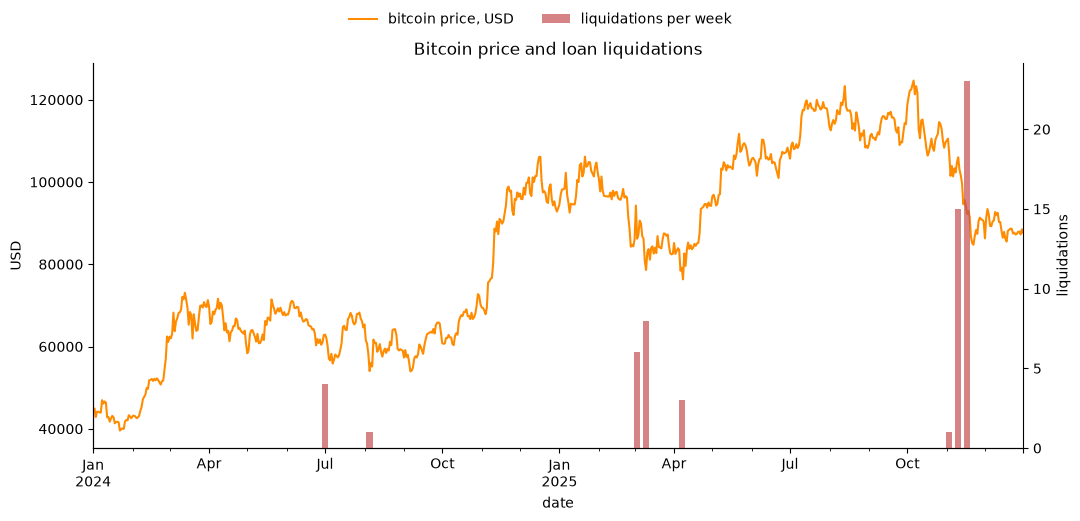

In [6]:
liquidated = loans[loans.status == "liquidated"]
fig, ax1 = plt.subplots(figsize=(12, 5))
btc.loc["2024-01":"2025-12"].plot(ax=ax1, color="darkorange", label="bitcoin price, USD")
ax1.set_ylabel("USD")
ax2 = ax1.twinx()
counts = liquidated.groupby(liquidated.closed.dt.to_period("W")).size()
ax2.bar(counts.index.to_timestamp(), counts.values, width=5, color="#c44e52", alpha=0.7, label="liquidations per week")
ax2.set_ylabel("liquidations")
ax2.spines["right"].set_visible(True)
ax1.set_title("Bitcoin price and loan liquidations")
fig.legend(loc="upper center", ncol=2, frameon=False)
plt.show()

In [7]:
liquidated.groupby(liquidated.closed.dt.to_period("M")).size().rename("liquidations")

closed
2024-07     4
2024-08     1
2025-03    14
2025-04     3
2025-11    39
Freq: M, Name: liquidations, dtype: int64

## 3. Loan amounts by outcome

In [8]:
loans["collateral_value_at_issue"] = loans.amount_eur / loans.ltv_at_issue
summary = loans.groupby("status").agg(loans=("loan_id", "size"), lent_eur=("amount_eur", "sum"),
                                     average_eur=("amount_eur", "mean"))
summary.round(0)

,loans,lent_eur,average_eur
status,,,
active,76,234470.0,3085.0
liquidated,61,211420.0,3466.0
repaid,371,1341820.0,3617.0


## Results

- Of 508 loans, 61 were liquidated, and every one of them started at 70% LTV; about 37% of the 70% loans ended that way. No loan starting at 30% or 50% was liquidated.
- Liquidations come in bursts on the days bitcoin fell sharply, most of all in November 2025.
- A 70% loan survives only an 18% price fall. The app could warn borrowers who choose it, or ask them to top up the collateral when LTV passes 75%, before the forced sale.

## Tools

Python, pandas, NumPy, matplotlib